# Recyclable Waste Classification: CNN vs. Transfer Learning on an Imbalanced Dataset

This notebook trains and evaluates image classifiers that recognise four categories of
recyclable waste (AluCan, Glass, HDPEM, PET) from the
[Drinking Waste Classification](https://www.kaggle.com/datasets/arkadiyhacks/drinking-waste-classification)
dataset. `waste_dataset.csv` selects a deliberately class-imbalanced subset of the dataset
(1000 AluCan / 1000 Glass / 1000 PET / 100 HDPEM). The notebook has three parts:

1. **Part 1** – partitioning the data into train/devtest/test sets and exploring the class distribution.
2. **Part 2** – training a CNN from scratch and a frozen pre-trained ResNet18, then comparing them.
3. **Part 3** – collecting new webcam/phone images of the minority class (HDPEM), balancing the
   training set with data augmentation, and fine-tuning the better system from Part 2.

The implementation uses standard PyTorch building blocks: `Dataset`/`DataLoader`,
`nn.Sequential` CNNs, a frozen pre-trained backbone with a replaced classification head,
`torchvision.transforms` augmentation, and small `Dataset` wrapper classes for oversampling
and on-the-fly augmentation.


## Setup

In [245]:
# Core imports: numpy/pandas for data handling, OpenCV for image I/O, PyTorch + torchvision for the models, sklearn for the split and metrics, matplotlib/seaborn for plots.
import os
import sys
import copy
import glob

import numpy as np
import pandas as pd
import cv2
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, ConcatDataset
from torchvision.models import resnet18, ResNet18_Weights
from torchvision import transforms

from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, accuracy_score, f1_score, recall_score

from matplotlib import pyplot as plt
import seaborn as sns
from tqdm import tqdm
from torchsummary import summary


In [246]:
# Project paths, the class list, and shared hyperparameters used throughout the notebook; the compute device (MPS/CUDA/CPU) is picked automatically.
BASE_DIR = os.getcwd()
DATA_ROOT = os.path.join(BASE_DIR, "Images_of_Waste", "rawimgs")  # AluCan Glass/HDPEM/PET subfolders
CSV_PATH = os.path.join(BASE_DIR, "waste_dataset.csv")

CLASSES = ["AluCan", "Glass", "HDPEM", "PET"]
SEED = 42

CNN_IMG_SIZE = 128       # from-scratch CNN input size (Part 2.1)
RESNET_IMG_SIZE = 224    # ResNet18 input size (Part 2.2)
BATCH_SIZE = 32

# ImageNet channel mean/std, used only for the pre-trained ResNet18 input.
IMAGENET_NORMALIZE = transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])

np.random.seed(SEED)
torch.manual_seed(SEED)

device = torch.device("mps" if torch.backends.mps.is_available()
                       else "cuda" if torch.cuda.is_available()
                       else "cpu")
print("Using device:", device)

Using device: mps


## Part 1 – Data exploration and preparation

### 1.1 Partition into training and test sets


In [247]:
# Stratified 60/20/20 split of waste_dataset.csv into train / devtest / test.
full_df = pd.read_csv(CSV_PATH)

train_df, remaining_df = train_test_split(
    full_df, test_size=0.4, stratify=full_df["label"], random_state=SEED
)
devtest_df, test_df = train_test_split(
    remaining_df, test_size=0.5, stratify=remaining_df["label"], random_state=SEED
)

train_df.to_csv(os.path.join(BASE_DIR, "train.csv"), index=False)
devtest_df.to_csv(os.path.join(BASE_DIR, "devtest.csv"), index=False)
test_df.to_csv(os.path.join(BASE_DIR, "test.csv"), index=False)

print(f"train:   {len(train_df):4d} images")
print(f"devtest: {len(devtest_df):4d} images")
print(f"test:    {len(test_df):4d} images")

train:   1860 images
devtest:  620 images
test:     620 images


**How the partition was made random and class-proportional.**

- `train_test_split` is called with `stratify=full_df["label"]`. This tells scikit-learn to
  split each class *separately* in the given proportion, rather than splitting the whole
  dataframe as one pool. As a result, every class ends up represented in train/devtest/test
  in (approximately) the same ratio as it appears in `waste_dataset.csv`, including the rare
  HDPEM class, which stays at roughly a 10:1 imbalance ratio against the other three classes
  in all three sets, rather than being split unevenly (e.g. all landing in one set) or being
  turned into a balanced class by construction.
- The partition is a **two-stage split** because `train_test_split` only produces two
  subsets at a time: first we split off 60% for `train` (leaving 40% "remaining"), then we
  split the remaining 40% evenly in half to get `devtest` (20% of the total) and `test`
  (20% of the total). Stratifying on both calls keeps the class proportions consistent at
  every stage.
- Randomness comes from scikit-learn's internal shuffling of each class's rows before
  splitting (this is the default behaviour of `train_test_split`, `shuffle=True`). We fix
  `random_state=SEED` purely so that the partition is *reproducible* across notebook runs;
  the split itself is still a random sample of the data, just one that will be identical
  every time this cell is executed.

Finally, keeping the *same proportion* of each class in every split is not the same as
making the classes *equal in size*. Because `waste_dataset.csv` itself is imbalanced
(1000/1000/100/1000), all three of `train.csv` / `devtest.csv` / `test.csv` are imbalanced in
that same 10:1 ratio. This is intended, not a bug: the devtest and test sets still reflect
the real, imbalanced distribution the model will be evaluated against, rather than giving an
artificially easy, class-balanced test.

### 1.2 Exploration

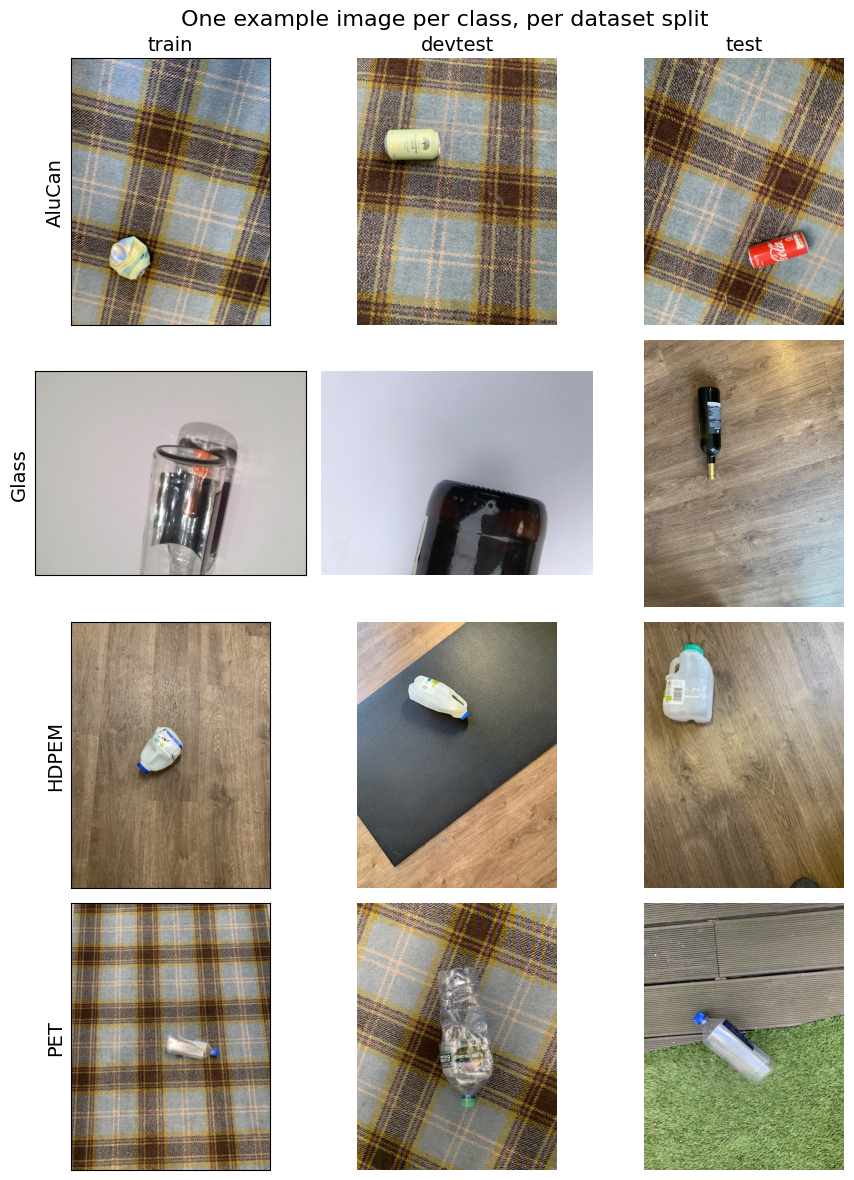

In [248]:
# Load one image per class from each split and lay them out in a 4x3 grid for Part 1.2's visual check.
def load_image_rgb(path):
    """Load an image (BGR on disk) and return it as an RGB uint8 array."""
    image = cv2.imread(path)
    return cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


def sample_image_path(df, class_name):
    """Return the full path of one image of the given class from df."""
    row = df[df["label"] == class_name].iloc[0]
    return os.path.join(DATA_ROOT, row["path"])


splits = {"train": train_df, "devtest": devtest_df, "test": test_df}

fig, axes = plt.subplots(len(CLASSES), len(splits), figsize=(3 * len(splits), 3 * len(CLASSES)))
for row_idx, class_name in enumerate(CLASSES):
    for col_idx, (split_name, split_df) in enumerate(splits.items()):
        img_path = sample_image_path(split_df, class_name)
        ax = axes[row_idx, col_idx]
        ax.imshow(load_image_rgb(img_path))
        ax.axis("off")
        if row_idx == 0:
            ax.set_title(split_name, fontsize=14)
        if col_idx == 0:
            ax.set_ylabel(class_name, fontsize=14)
            ax.axis("on")
            ax.set_xticks([])
            ax.set_yticks([])
fig.suptitle("One example image per class, per dataset split", fontsize=16)
plt.tight_layout()
plt.show()

In [249]:
# Build and display the per-class, per-split image-count table, plus the max:min imbalance ratio row.
def class_counts_table(splits):
    counts = pd.DataFrame({name: df["label"].value_counts() for name, df in splits.items()})
    counts = counts.reindex(CLASSES)
    counts.loc["Imbalance ratio (max:min)"] = counts.loc[CLASSES].max() / counts.loc[CLASSES].min()
    return counts


counts_table = class_counts_table(splits)
display(counts_table)

,train,devtest,test
label,,,
AluCan,600.0,200.0,200.0
Glass,600.0,200.0,200.0
HDPEM,60.0,20.0,20.0
PET,600.0,200.0,200.0
Imbalance ratio (max:min),10.0,10.0,10.0


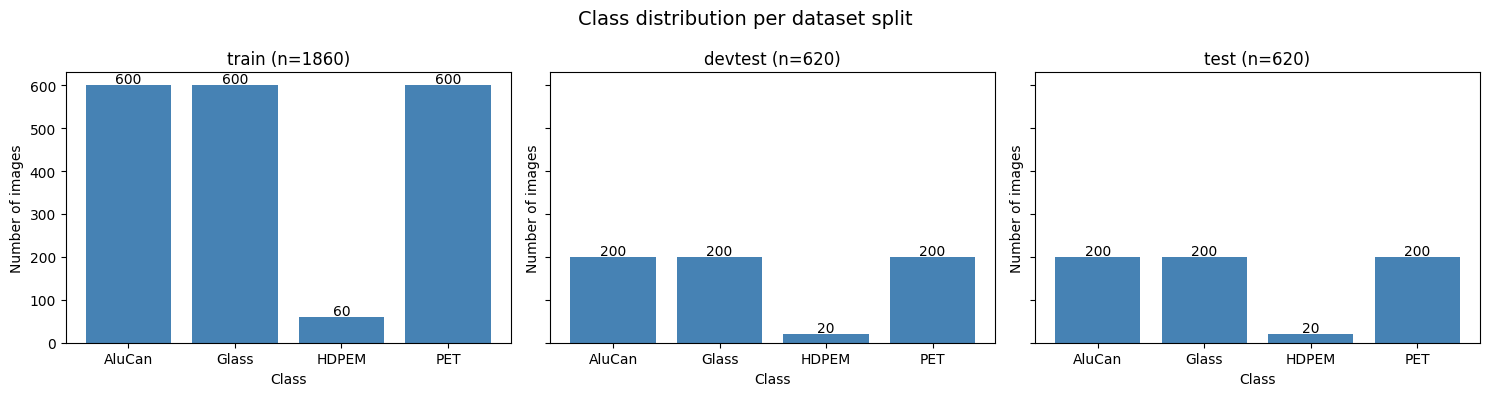

In [250]:
# Bar chart of class counts per split, with each bar's exact count labelled on top.
fig, axes = plt.subplots(1, len(splits), figsize=(5 * len(splits), 4), sharey=True)
for ax, (split_name, split_df) in zip(axes, splits.items()):
    class_counts = split_df["label"].value_counts().reindex(CLASSES)
    ax.bar(CLASSES, class_counts.values, color="steelblue")
    ax.set_title(f"{split_name} (n={len(split_df)})")
    ax.set_xlabel("Class")
    ax.set_ylabel("Number of images")
    for i, v in enumerate(class_counts.values):
        ax.text(i, v + 5, str(v), ha="center")
fig.suptitle("Class distribution per dataset split", fontsize=14)
plt.tight_layout()
plt.show()


**Discussion of the class distribution.**

HDPEM is by far the rarest class: it makes up only 100 of the 3,100 sampled images
(about 3.2%), against 1,000 each (about 32.3%) for AluCan, Glass and PET. That is a 10:1
imbalance ratio, and it is preserved across all three splits by the stratified partition
above. In the test set specifically, this leaves only **20 HDPEM images** to measure
performance on (20% of the 100 total), compared to 200 images for each of the other classes.

With so few HDPEM examples, we should expect several problems when training a classifier:

- **The model has little signal to learn HDPEM-specific visual features from** (only 60
  training images), so it is likely to under-perform on HDPEM relative to the other classes.
- **A classifier can reach high overall accuracy while doing very poorly on HDPEM**, simply
  by rarely predicting it, because accuracy is dominated by the three majority classes, which
  make up about 97% of the data. This is why we also report macro-F1 and per-class recall in
  Part 2.3, rather than relying on accuracy alone.
- **With only 20 HDPEM test images, recall and F1 estimates for that class are noisy.** One
  or two extra misclassified images move the HDPEM recall by 5 percentage points, so small
  differences in HDPEM performance between models should not be over-interpreted.
- This motivates Part 3, where we collect extra real HDPEM images and use data augmentation
  to even out the training set.

## Part 2 – Classification

Both classifiers below share the same `Dataset` class, training loop and evaluation
helpers, so the two systems are trained and measured the same way and can be compared
fairly. Only the architecture differs between 2.1 and 2.2, plus one preprocessing
difference: ResNet18's input is normalised with ImageNet's per-channel mean/std
(`IMAGENET_NORMALIZE`), which an ImageNet-pretrained backbone needs in order to work well,
whereas the from-scratch CNN does not use this normalisation.

In [251]:
# Dataset that reads an image by its path, resizes it, scales it to [0, 1], and optionally applies ImageNet normalisation for the ResNet pipeline.
class WasteDataset(Dataset):
    """(image, label) pairs from a path/label CSV such as train.csv.

    `normalize` is an optional transform applied after the image is scaled to [0, 1];
    used for the pre-trained ResNet18 pipeline only.
    """

    def __init__(self, dataframe, data_root, classes, img_size, normalize=None):
        super().__init__()
        self.df = dataframe.reset_index(drop=True)
        self.data_root = data_root
        self.classes = classes
        self.img_size = img_size
        self.normalize = normalize

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = load_image_rgb(os.path.join(self.data_root, row["path"]))
        image = cv2.resize(image, (self.img_size, self.img_size))
        image = torch.tensor(image / 255).permute(2, 0, 1).float()
        if self.normalize is not None:
            image = self.normalize(image)
        label = self.classes.index(row["label"])
        return image, label

In [252]:
# Shared training utilities: one training epoch, plain evaluation, macro-F1 scoring, the early-stopping fit() loop, and a loss/accuracy plotting helper reused by both Part 2 models and the Part 3.3 fine-tuning step.
def train_one_epoch(model, loader, optimizer, loss_fn, device):
    model.train()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in tqdm(loader, desc="train", leave=False):
        images, labels = images.to(device), labels.to(device)
        optimizer.zero_grad()
        outputs = model(images)
        loss = loss_fn(outputs, labels)
        loss.backward()
        optimizer.step()
        total_loss += loss.item() * len(labels)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += len(labels)
    return total_loss / total, correct / total


@torch.no_grad()
def evaluate(model, loader, loss_fn, device):
    model.eval()
    total_loss, correct, total = 0.0, 0, 0
    for images, labels in loader:
        images, labels = images.to(device), labels.to(device)
        outputs = model(images)
        loss = loss_fn(outputs, labels)
        total_loss += loss.item() * len(labels)
        correct += (outputs.argmax(1) == labels).sum().item()
        total += len(labels)
    return total_loss / total, correct / total


@torch.no_grad()
def macro_f1_score(model, loader, device):
    """Macro-F1 of `model` over `loader` (alternative early-stopping metric to accuracy)."""
    model.eval()
    y_true, y_pred = [], []
    for images, labels in loader:
        images = images.to(device)
        outputs = model(images)
        y_true.extend(labels.numpy().tolist())
        y_pred.extend(outputs.argmax(1).cpu().numpy().tolist())
    return f1_score(y_true, y_pred, average="macro")


def fit(model, train_loader, val_loader, device, max_epochs=30, patience=5, lr=1e-3, monitor="accuracy"):
    """Train with early stopping on the devtest set (stop after `patience` epochs with no
    improvement), then restore the best epoch's weights. `monitor` is "accuracy" or
    "macro_f1"; 3.3 uses "macro_f1" because accuracy is insensitive to the small HDPEM
    class. Returns the per-epoch history."""
    trainable_params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.Adam(trainable_params, lr=lr)
    loss_fn = nn.CrossEntropyLoss()

    history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
    best_monitor_value = -1.0
    best_state = copy.deepcopy(model.state_dict())
    epochs_without_improvement = 0

    for epoch in range(1, max_epochs + 1):
        train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, loss_fn, device)
        val_loss, val_acc = evaluate(model, val_loader, loss_fn, device)
        monitor_value = macro_f1_score(model, val_loader, device) if monitor == "macro_f1" else val_acc

        history["train_loss"].append(train_loss)
        history["train_acc"].append(train_acc)
        history["val_loss"].append(val_loss)
        history["val_acc"].append(val_acc)
        print(f"Epoch {epoch:2d}: train_loss={train_loss:.4f} train_acc={train_acc:.4f} "
              f"| val_loss={val_loss:.4f} val_acc={val_acc:.4f} | val_{monitor}={monitor_value:.4f}")

        if monitor_value > best_monitor_value:
            best_monitor_value = monitor_value
            best_state = copy.deepcopy(model.state_dict())
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1
            if epochs_without_improvement >= patience:
                print(f"No devtest improvement for {patience} epochs -- stopping early "
                      f"at epoch {epoch} (best val_{monitor}={best_monitor_value:.4f}).")
                break

    model.load_state_dict(best_state)
    return history


def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(history["train_loss"], marker="o", label="train")
    axes[0].plot(history["val_loss"], marker="o", label="devtest")
    axes[0].set_title(f"{title} - Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].set_ylabel("Loss")
    axes[0].legend()

    axes[1].plot(history["train_acc"], marker="o", label="train")
    axes[1].plot(history["val_acc"], marker="o", label="devtest")
    axes[1].set_title(f"{title} - Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].set_ylabel("Accuracy")
    axes[1].legend()

    plt.tight_layout()
    plt.show()

### 2.1 Using ConvNets

The architecture is a stack of three `Conv2d -> MaxPool2d(2) -> ReLU` blocks followed by a
classification head. The number of filters increases across the blocks (32, 64, 128), so the
network learns progressively more abstract features as the spatial resolution shrinks.
`padding=1` keeps each convolution's output the same spatial size as its input, so the only
downsampling comes from the three `MaxPool2d(2)` layers: 128 -> 64 -> 32 -> 16. The final
128 x 16 x 16 feature map is flattened to 32,768 values (see the model summary below), passed
through `Dropout(0.5)`, and mapped to the four class logits by a single `Linear` layer.

The only input preprocessing is scaling pixels to `[0, 1]` inside `WasteDataset`. No ImageNet
normalisation is applied, because this network is trained from scratch rather than reusing a
pre-trained backbone.

In [253]:
# Wrap the three splits in WasteDataset/DataLoader at the CNN's input size, then build and summarise the from-scratch Conv-Pool-ReLU network for Part 2.1.
train_ds_cnn = WasteDataset(train_df, DATA_ROOT, CLASSES, CNN_IMG_SIZE)
devtest_ds_cnn = WasteDataset(devtest_df, DATA_ROOT, CLASSES, CNN_IMG_SIZE)
test_ds_cnn = WasteDataset(test_df, DATA_ROOT, CLASSES, CNN_IMG_SIZE)

train_loader_cnn = DataLoader(train_ds_cnn, batch_size=BATCH_SIZE, shuffle=True)
devtest_loader_cnn = DataLoader(devtest_ds_cnn, batch_size=BATCH_SIZE, shuffle=False)
test_loader_cnn = DataLoader(test_ds_cnn, batch_size=BATCH_SIZE, shuffle=False)


def build_cnn(num_classes, img_size, dropout=0.5):
    final_size = img_size // 8  # after 3 MaxPool2d(2) layers
    return nn.Sequential(
        nn.Conv2d(3, 32, kernel_size=3, padding=1),
        nn.MaxPool2d(2),
        nn.ReLU(),
        nn.Conv2d(32, 64, kernel_size=3, padding=1),
        nn.MaxPool2d(2),
        nn.ReLU(),
        nn.Conv2d(64, 128, kernel_size=3, padding=1),
        nn.MaxPool2d(2),
        nn.ReLU(),
        nn.Flatten(),
        nn.Dropout(dropout),  # regularisation against overfitting
        nn.Linear(128 * final_size * final_size, num_classes),
    )


cnn_model = build_cnn(len(CLASSES), CNN_IMG_SIZE).to(device)
summary(cnn_model.to("cpu"), (3, CNN_IMG_SIZE, CNN_IMG_SIZE))  # torchsummary needs the model on CPU
cnn_model = cnn_model.to(device)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 32, 128, 128]             896
         MaxPool2d-2           [-1, 32, 64, 64]               0
              ReLU-3           [-1, 32, 64, 64]               0
            Conv2d-4           [-1, 64, 64, 64]          18,496
         MaxPool2d-5           [-1, 64, 32, 32]               0
              ReLU-6           [-1, 64, 32, 32]               0
            Conv2d-7          [-1, 128, 32, 32]          73,856
         MaxPool2d-8          [-1, 128, 16, 16]               0
              ReLU-9          [-1, 128, 16, 16]               0
          Flatten-10                [-1, 32768]               0
          Dropout-11                [-1, 32768]               0
           Linear-12                    [-1, 4]         131,076
Total params: 224,324
Trainable params: 224,324
Non-trainable params: 0
-------------------------------

Epoch  1: train_loss=1.1479 train_acc=0.4586 | val_loss=1.0137 val_acc=0.5694 | val_accuracy=0.5694


Epoch  2: train_loss=0.9456 train_acc=0.6086 | val_loss=0.9398 val_acc=0.6242 | val_accuracy=0.6242


Epoch  3: train_loss=0.7980 train_acc=0.6941 | val_loss=0.7923 val_acc=0.6935 | val_accuracy=0.6935


Epoch  4: train_loss=0.6642 train_acc=0.7548 | val_loss=0.6810 val_acc=0.7484 | val_accuracy=0.7484


Epoch  5: train_loss=0.6021 train_acc=0.7667 | val_loss=0.6506 val_acc=0.7710 | val_accuracy=0.7710


...

Epoch 13: train_loss=0.2010 train_acc=0.9301 | val_loss=0.7926 val_acc=0.8177 | val_accuracy=0.8177


Epoch 14: train_loss=0.1786 train_acc=0.9425 | val_loss=0.7706 val_acc=0.7823 | val_accuracy=0.7823


Epoch 15: train_loss=0.2137 train_acc=0.9220 | val_loss=0.6736 val_acc=0.8032 | val_accuracy=0.8032


Epoch 16: train_loss=0.1600 train_acc=0.9484 | val_loss=0.6996 val_acc=0.8145 | val_accuracy=0.8145


Epoch 17: train_loss=0.1353 train_acc=0.9532 | val_loss=0.7229 val_acc=0.8016 | val_accuracy=0.8016
No devtest improvement for 5 epochs -- stopping early at epoch 17 (best val_accuracy=0.8258).


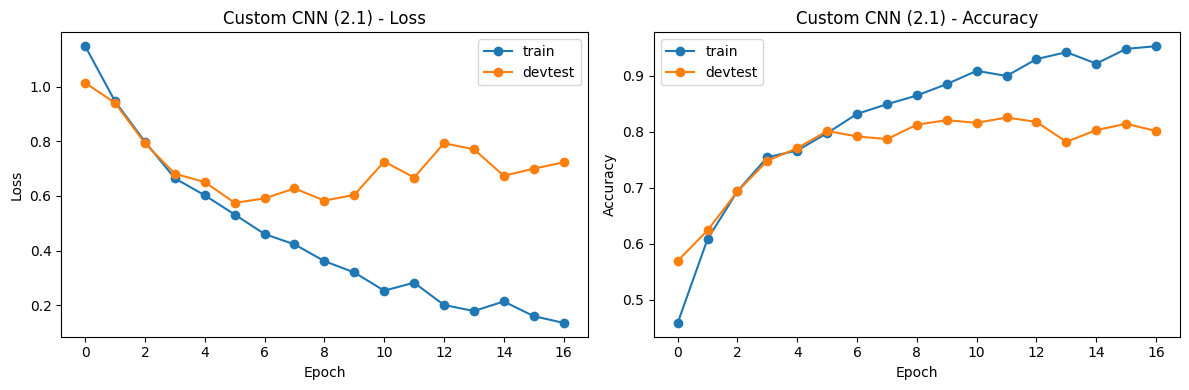

In [254]:
# Train the custom CNN with early stopping on devtest, then plot its loss/accuracy curves.
cnn_history = fit(cnn_model, train_loader_cnn, devtest_loader_cnn, device, max_epochs=30, patience=5)
plot_history(cnn_history, "Custom CNN (2.1)")


In [255]:
# Evaluate the trained CNN on the held-out test set -- only touched here, at the very end.
cnn_test_loss, cnn_test_acc = evaluate(cnn_model, test_loader_cnn, nn.CrossEntropyLoss(), device)
print(f"Custom CNN - test loss: {cnn_test_loss:.4f}, test accuracy: {cnn_test_acc:.4f}")
print(f"Custom CNN - final train accuracy: {cnn_history['train_acc'][-1]:.4f}")


Custom CNN - test loss: 0.5866, test accuracy: 0.8242
Custom CNN - final train accuracy: 0.9532


In [256]:
# Dropout ablation: same CNN with dropout=0.0; RNG is saved and restored so 2.2 is unaffected.
_cpu_rng_state = torch.get_rng_state()
_mps_rng_state = torch.mps.get_rng_state() if device.type == "mps" else None

torch.manual_seed(SEED)
cnn_no_dropout = build_cnn(len(CLASSES), CNN_IMG_SIZE, dropout=0.0).to(device)
no_dropout_history = fit(cnn_no_dropout, train_loader_cnn, devtest_loader_cnn, device,
                         max_epochs=30, patience=5)
_, cnn_no_dropout_test_acc = evaluate(cnn_no_dropout, test_loader_cnn,
                                      nn.CrossEntropyLoss(), device)

torch.set_rng_state(_cpu_rng_state)
if _mps_rng_state is not None:
    torch.mps.set_rng_state(_mps_rng_state)

dropout_ablation = pd.DataFrame({
    "configuration": ["without Dropout", "with Dropout(0.5)"],
    "final train accuracy": [no_dropout_history["train_acc"][-1], cnn_history["train_acc"][-1]],
    "test accuracy": [cnn_no_dropout_test_acc, cnn_test_acc],
})
dropout_ablation["train - test gap"] = (
    dropout_ablation["final train accuracy"] - dropout_ablation["test accuracy"]
)
print("Effect of the Dropout(0.5) layer (same architecture, data and training procedure):")
display(dropout_ablation.round(4))

Epoch  1: train_loss=1.1309 train_acc=0.4688 | val_loss=0.9654 val_acc=0.6355 | val_accuracy=0.6355


Epoch  2: train_loss=0.8795 train_acc=0.6694 | val_loss=0.8241 val_acc=0.6597 | val_accuracy=0.6597


Epoch  3: train_loss=0.7394 train_acc=0.7183 | val_loss=0.7831 val_acc=0.7113 | val_accuracy=0.7113


Epoch  4: train_loss=0.6793 train_acc=0.7462 | val_loss=0.6673 val_acc=0.7500 | val_accuracy=0.7500


Epoch  5: train_loss=0.5684 train_acc=0.7817 | val_loss=0.6757 val_acc=0.7355 | val_accuracy=0.7355


...

Epoch 15: train_loss=0.1781 train_acc=0.9387 | val_loss=0.9104 val_acc=0.7548 | val_accuracy=0.7548


Epoch 16: train_loss=0.1455 train_acc=0.9511 | val_loss=0.9258 val_acc=0.7758 | val_accuracy=0.7758


Epoch 17: train_loss=0.1328 train_acc=0.9500 | val_loss=0.8086 val_acc=0.8097 | val_accuracy=0.8097


Epoch 18: train_loss=0.0833 train_acc=0.9758 | val_loss=0.8850 val_acc=0.7952 | val_accuracy=0.7952
No devtest improvement for 5 epochs -- stopping early at epoch 18 (best val_accuracy=0.8258).
Effect of the Dropout(0.5) layer (same architecture, data and training procedure):


,configuration,final train accuracy,test accuracy,train - test gap
0,without Dropout,0.9758,0.8048,0.171
1,with Dropout(0.5),0.9532,0.8242,0.129


**Hyperparameter choices and how overfitting was assessed.**

*Convolution hyperparameters.* Filters of 32/64/128, a 3x3 kernel and 2x2 max-pooling are
standard defaults for small image classifiers. Doubling the filter count each time a pooling
layer halves the spatial resolution keeps the amount of computation roughly balanced across
the three blocks.

*Input size 128x128.* Compute per epoch grows roughly with the square of the input side, so
128x128 keeps training fast while still resolving the labels, textures and shapes that
separate the four packaging materials. Smaller inputs blur those cues; larger inputs mainly
cost time on this task.

*Optimiser.* Adam with its default learning rate (1e-3). It adapts the step size per
parameter and converges reliably here without a manual learning-rate schedule.

*Dropout (0.5) before the classification layer.* The cell above is an ablation: the identical
architecture trained with the dropout layer removed (`dropout=0.0`), with the same data, the
same optimiser and the same early stopping. Without dropout the model reaches 97.58% training
accuracy but only 80.48% test accuracy, a 17.1-point train/test gap. Adding `Dropout(0.5)`
lowers training accuracy to 95.32% and raises test accuracy to 82.42%, narrowing the gap to
12.9 points. Dropout is doing its job here: it curbs memorisation of the training set and, in
this run, also improves generalisation slightly.

*When to stop training.* Instead of a fixed epoch count, training runs for up to 30 epochs
and stops once devtest accuracy has not improved for 5 consecutive epochs, after which the
best epoch's weights are restored. In this run it stopped at epoch 17 and restored the
epoch-12 weights (best devtest accuracy 0.8258). The test set is not touched until the final
evaluation in the next cell.

*Evidence of overfitting.* The loss curves show the classic pattern. Devtest loss reaches its
minimum near epoch 6 (about 0.57) and then climbs back to about 0.72 by epoch 17, while
training loss keeps falling (from about 0.53 to 0.14). The final 95.32% train versus 82.42%
test accuracy (a 12.9-point gap) confirms residual overfitting even after dropout and early
stopping. With only 1,860 training images across four classes, and just 60 for HDPEM at this
stage, a from-scratch CNN has limited material to generalise from, which is the most likely
reason the gap does not close further.

### 2.2 Using pre-trained models

We use ResNet18 pre-trained on ImageNet, freeze every parameter
(`param.requires_grad = False` across the whole backbone), and replace the final
fully-connected layer with a new `nn.Linear` sized for our four classes. The model summary
below confirms the split: 11,176,512 frozen backbone parameters and only 2,052 trainable
parameters in the new head.

Freezing the backbone avoids **catastrophic forgetting**, where continuing to train a
pre-trained network on a small new dataset overwrites the general visual features it already
holds. Only the new classification layer learns, so the network keeps ResNet18's ImageNet
features (edges, textures, shapes) and only learns how to map them onto the four waste
categories. That needs far fewer parameters, and far less data, than training a CNN from
scratch. The input is normalised with ImageNet's per-channel mean and standard deviation
(`IMAGENET_NORMALIZE`), because that is the distribution the frozen backbone expects.

In [257]:
# Same data pipeline as 2.1 but at ResNet's 224px input with ImageNet normalisation; build the frozen-backbone ResNet18 and confirm the parameter split in the summary.
train_ds_resnet = WasteDataset(train_df, DATA_ROOT, CLASSES, RESNET_IMG_SIZE, normalize=IMAGENET_NORMALIZE)
devtest_ds_resnet = WasteDataset(devtest_df, DATA_ROOT, CLASSES, RESNET_IMG_SIZE, normalize=IMAGENET_NORMALIZE)
test_ds_resnet = WasteDataset(test_df, DATA_ROOT, CLASSES, RESNET_IMG_SIZE, normalize=IMAGENET_NORMALIZE)

train_loader_resnet = DataLoader(train_ds_resnet, batch_size=BATCH_SIZE, shuffle=True)
devtest_loader_resnet = DataLoader(devtest_ds_resnet, batch_size=BATCH_SIZE, shuffle=False)
test_loader_resnet = DataLoader(test_ds_resnet, batch_size=BATCH_SIZE, shuffle=False)


def build_resnet18(num_classes):
    model = resnet18(weights=ResNet18_Weights.IMAGENET1K_V1)
    for param in model.parameters():
        param.requires_grad = False  # freeze the pre-trained backbone
    model.fc = nn.Linear(model.fc.in_features, num_classes)  # new trainable head
    return model


resnet_model = build_resnet18(len(CLASSES)).to(device)
summary(resnet_model.to("cpu"), (3, RESNET_IMG_SIZE, RESNET_IMG_SIZE))  # torchsummary needs the model on CPU
resnet_model = resnet_model.to(device)

----------------------------------------------------------------
        Layer (type)               Output Shape         Param #
            Conv2d-1         [-1, 64, 112, 112]           9,408
       BatchNorm2d-2         [-1, 64, 112, 112]             128
              ReLU-3         [-1, 64, 112, 112]               0
         MaxPool2d-4           [-1, 64, 56, 56]               0
            Conv2d-5           [-1, 64, 56, 56]          36,864
       BatchNorm2d-6           [-1, 64, 56, 56]             128
              ReLU-7           [-1, 64, 56, 56]               0
            Conv2d-8           [-1, 64, 56, 56]          36,864
       BatchNorm2d-9           [-1, 64, 56, 56]             128
             ReLU-10           [-1, 64, 56, 56]               0
       BasicBlock-11           [-1, 64, 56, 56]               0
           Conv2d-12           [-1, 64, 56, 56]          36,864
      BatchNorm2d-13           [-1, 64, 56, 56]             128
             ReLU-14           [-1, 64,

Epoch  1: train_loss=0.9171 train_acc=0.6478 | val_loss=0.6325 val_acc=0.8113 | val_accuracy=0.8113


Epoch  2: train_loss=0.5972 train_acc=0.8022 | val_loss=0.4805 val_acc=0.8548 | val_accuracy=0.8548


Epoch  3: train_loss=0.4877 train_acc=0.8441 | val_loss=0.4375 val_acc=0.8661 | val_accuracy=0.8661


Epoch  4: train_loss=0.4345 train_acc=0.8489 | val_loss=0.3847 val_acc=0.8694 | val_accuracy=0.8694


Epoch  5: train_loss=0.3919 train_acc=0.8812 | val_loss=0.3336 val_acc=0.9032 | val_accuracy=0.9032


...

Epoch 23: train_loss=0.1898 train_acc=0.9409 | val_loss=0.2352 val_acc=0.9242 | val_accuracy=0.9242


Epoch 24: train_loss=0.1682 train_acc=0.9505 | val_loss=0.2178 val_acc=0.9339 | val_accuracy=0.9339


Epoch 25: train_loss=0.1729 train_acc=0.9468 | val_loss=0.2124 val_acc=0.9290 | val_accuracy=0.9290


Epoch 26: train_loss=0.1700 train_acc=0.9478 | val_loss=0.2079 val_acc=0.9339 | val_accuracy=0.9339


Epoch 27: train_loss=0.1614 train_acc=0.9538 | val_loss=0.2181 val_acc=0.9323 | val_accuracy=0.9323
No devtest improvement for 5 epochs -- stopping early at epoch 27 (best val_accuracy=0.9339).


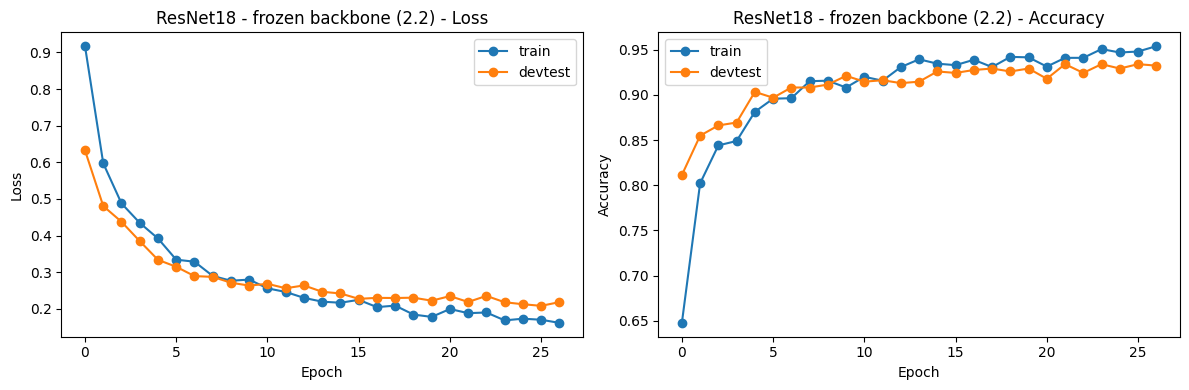

In [258]:
# Train only ResNet18's new head with the same early-stopping procedure, then plot its curves.
resnet_history = fit(resnet_model, train_loader_resnet, devtest_loader_resnet, device, max_epochs=30, patience=5)
plot_history(resnet_history, "ResNet18 - frozen backbone (2.2)")


In [259]:
# Evaluate ResNet18 on the test set and print a quick side-by-side accuracy comparison with the CNN.
resnet_test_loss, resnet_test_acc = evaluate(resnet_model, test_loader_resnet, nn.CrossEntropyLoss(), device)
print(f"ResNet18 - test loss: {resnet_test_loss:.4f}, test accuracy: {resnet_test_acc:.4f}")
print(f"ResNet18 - final train accuracy: {resnet_history['train_acc'][-1]:.4f}")

print()
print(f"{'Model':<20}{'Test accuracy':>15}")
print(f"{'Custom CNN (2.1)':<20}{cnn_test_acc:>15.4f}")
print(f"{'ResNet18 (2.2)':<20}{resnet_test_acc:>15.4f}")


ResNet18 - test loss: 0.2427, test accuracy: 0.9242
ResNet18 - final train accuracy: 0.9538

Model                 Test accuracy
Custom CNN (2.1)             0.8242
ResNet18 (2.2)               0.9242


**Comparing the two systems.**

Both models use the same training data, the same optimiser, the same maximum epoch count and
the same devtest-based early stopping, so the comparison is like-for-like. The only
differences are the architecture and the ImageNet input normalisation that ResNet18's frozen
backbone requires.

| Model | Test accuracy | Train accuracy | Train/test gap | Macro-F1 |
|---|---|---|---|---|
| Custom CNN (2.1), with dropout | 82.42% | 95.32% | ~12.9 points | 69.42% |
| ResNet18, frozen backbone (2.2) | 92.42% | 95.38% | ~3.0 points | 90.10% |

**ResNet18 is clearly the better system.** It beats the from-scratch CNN by exactly 10
accuracy points (92.42% versus 82.42%) and by more than 20 macro-F1 points (90.10% versus
69.42%), even though only its 2,052-parameter classification head is trained and the rest of
the network stays frozen at its ImageNet weights.

It also generalises better. Its train/test gap of about 3.0 points is roughly a quarter of
the CNN's 12.9 points. The frozen backbone cannot memorise our small training set, whereas
the from-scratch CNN has to learn every filter from only 1,860 images and fits the training
data well without matching that on the test set. ResNet18's ImageNet features already encode
general-purpose edges, textures and shapes that transfer well to separating aluminium cans,
glass, HDPE and PET. Part 2.3 breaks this down per class with confusion matrices, macro-F1
and per-class recall.

### 2.3 Error analysis

In [260]:
# Shared error-analysis helper: collect predictions, plot a confusion matrix, report accuracy/macro-F1/per-class recall, and show 5 examples of the single most common mistake.
@torch.no_grad()
def get_predictions(model, loader, device):
    """(y_true, y_pred) as index arrays in dataset order (needs a shuffle=False loader)."""
    model.eval()
    y_true, y_pred = [], []
    for images, labels in loader:
        images = images.to(device)
        outputs = model(images)
        y_true.extend(labels.numpy().tolist())
        y_pred.extend(outputs.argmax(1).cpu().numpy().tolist())
    return np.array(y_true), np.array(y_pred)


def error_analysis(model, model_name, test_loader, test_dataframe, device):
    y_true, y_pred = get_predictions(model, test_loader, device)

    cm = confusion_matrix(y_true, y_pred, labels=range(len(CLASSES)))
    fig, ax = plt.subplots(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("True label")
    ax.set_title(f"{model_name} - confusion matrix (test set)")
    plt.tight_layout()
    plt.show()

    accuracy = accuracy_score(y_true, y_pred)
    macro_f1 = f1_score(y_true, y_pred, average="macro")
    per_class_recall = recall_score(y_true, y_pred, average=None, labels=range(len(CLASSES)))
    support = pd.Series(y_true).value_counts().reindex(range(len(CLASSES))).fillna(0).astype(int)

    metrics_table = pd.DataFrame({
        "class": CLASSES,
        "recall": per_class_recall,
        "test images (support)": support.values,
    })
    metrics_table.loc["Overall"] = ["Overall", np.nan, support.sum()]
    metrics_table["accuracy"] = accuracy
    metrics_table["macro_F1"] = macro_f1
    metrics_table = metrics_table[["class", "accuracy", "macro_F1", "recall", "test images (support)"]]
    print(f"\n{model_name} - test set metrics")
    display(metrics_table)

    cm_no_diag = cm.copy()
    np.fill_diagonal(cm_no_diag, 0)
    true_idx, pred_idx = np.unravel_index(cm_no_diag.argmax(), cm_no_diag.shape)
    n_errors = cm_no_diag[true_idx, pred_idx]
    true_class, pred_class = CLASSES[true_idx], CLASSES[pred_idx]
    print(f"Most common error: true={true_class!r} predicted as {pred_class!r} "
          f"({n_errors} test images)")

    error_positions = np.where((y_true == true_idx) & (y_pred == pred_idx))[0][:5]
    fig, axes = plt.subplots(1, len(error_positions), figsize=(3 * len(error_positions), 3))
    if len(error_positions) == 1:
        axes = [axes]
    for ax, pos in zip(axes, error_positions):
        row = test_dataframe.iloc[pos]
        img = load_image_rgb(os.path.join(DATA_ROOT, row["path"]))
        ax.imshow(img)
        ax.axis("off")
        ax.set_title(f"true={true_class}\npred={pred_class}")
    fig.suptitle(f"{model_name} - examples of the most common error", fontsize=13)
    plt.tight_layout()
    plt.show()

    return {"accuracy": accuracy, "macro_f1": macro_f1, "confusion_matrix": cm,
            "y_true": y_true, "y_pred": y_pred}

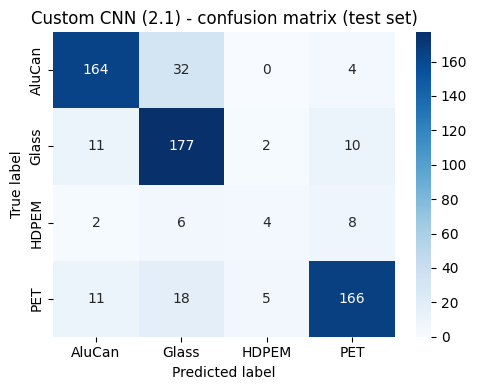


Custom CNN (2.1) - test set metrics


,class,accuracy,macro_F1,recall,test images (support)
0,AluCan,0.824194,0.694162,0.820,200
1,Glass,0.824194,0.694162,0.885,200
2,HDPEM,0.824194,0.694162,0.200,20
3,PET,0.824194,0.694162,0.830,200
Overall,Overall,0.824194,0.694162,NaN,620


Most common error: true='AluCan' predicted as 'Glass' (32 test images)


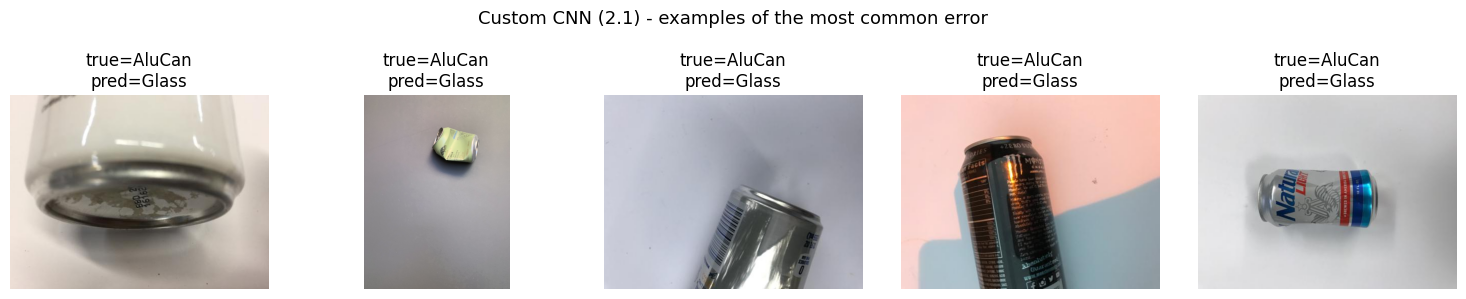

In [261]:
# Run the error analysis for the custom CNN (Part 2.3).
cnn_results = error_analysis(cnn_model, "Custom CNN (2.1)", test_loader_cnn, test_df, device)


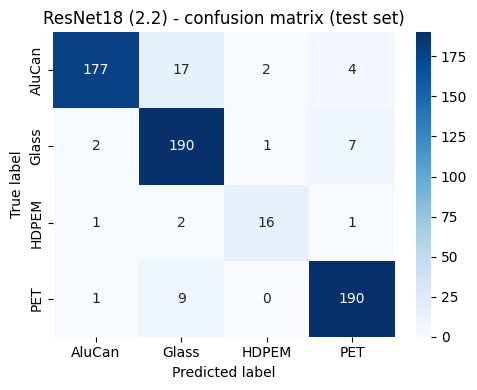


ResNet18 (2.2) - test set metrics


,class,accuracy,macro_F1,recall,test images (support)
0,AluCan,0.924194,0.901003,0.885,200
1,Glass,0.924194,0.901003,0.950,200
2,HDPEM,0.924194,0.901003,0.800,20
3,PET,0.924194,0.901003,0.950,200
Overall,Overall,0.924194,0.901003,NaN,620


Most common error: true='AluCan' predicted as 'Glass' (17 test images)


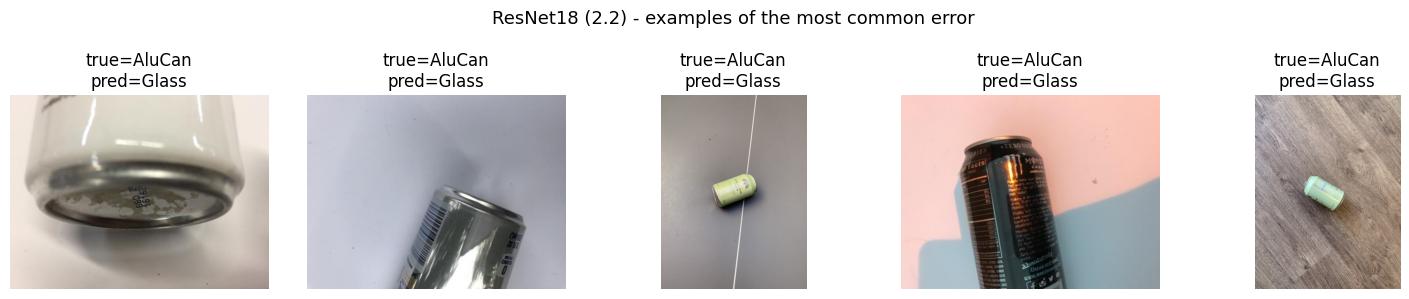

In [262]:
# Run the same error analysis for ResNet18, for a direct comparison with the CNN above.
resnet_results = error_analysis(resnet_model, "ResNet18 (2.2)", test_loader_resnet, test_df, device)


**Significant differences between the two systems.**

The two confusion matrices and metrics tables above show three clear differences:

1. **Overall performance.** ResNet18 (92.42% accuracy, 90.10% macro-F1) beats the custom CNN
   (82.42% accuracy, 69.42% macro-F1) on every metric, confirming the Part 2.2 comparison.
2. **HDPEM recall.** This is where the gap is widest. ResNet18 reaches 80.0% HDPEM recall
   (16 of 20 correct) against the CNN's 20.0% (4 of 20). ResNet18's pre-trained features
   generalise to the minority class far better than filters learned from only 60 from-scratch
   HDPEM training images.
3. **Most common error.** Both models' single most common error is the same pair: true
   `AluCan` predicted as `Glass`. The scale differs sharply, 32 test images for the CNN versus
   17 for ResNet18, out of 200 AluCan test images. Both models find aluminium cans and glass
   bottles confusable (similar cylindrical shape and reflective surfaces under some lighting),
   but ResNet18 is markedly more robust to it.

**Gap between accuracy and macro-F1, and the worst class.**

Both models score higher on accuracy than on macro-F1, and the gap is much larger for the
custom CNN (82.42% - 69.42% = 13.0 points) than for ResNet18 (92.42% - 90.10% = 2.3 points).
This is the imbalance effect from the Part 1.2 discussion. The test set holds 200 / 200 / 20 /
200 images per class, so overall accuracy is dominated by the three majority classes and
HDPEM is only 3.2% of it, whereas macro-F1 averages the four per-class F1 scores equally. The
CNN's 20% HDPEM recall costs its accuracy almost nothing but pulls its macro-F1 down hard, so
a large accuracy/macro-F1 gap is a warning sign that headline accuracy is hiding a weak
minority class.

In both models **HDPEM is the worst class by a wide margin**: 20.0% recall for the CNN and
80.0% for ResNet18, against 82-88% for the CNN's other classes and 88-95% for ResNet18's.
This matches the Part 1.2 prediction. HDPEM had only 60 training images (10x fewer than the
other classes) and only 20 test images, so the models see too few examples to learn robust
features, and each single misclassified test image moves HDPEM recall by 5 points. Part 3
addresses exactly this: collect more real HDPEM images and use data augmentation to rebalance
the training set, then re-evaluate on the same test set to see whether HDPEM recall improves
without hurting the other classes.

## Part 3 – Deployment to a webcam

### 3.1 Generate new images for the minority class

To reduce the HDPEM class imbalance, at least 150 new HDPEM photos are collected: some with
a laptop webcam (`capture_webcam.py`) and the rest with a phone/other camera
(`import_phone_photos.py`, which also converts iPhone `.HEIC` photos to `.jpg`). This does **not**
require 150 different physical items -- around 30 real
HDPE items (bottles, containers, etc.), reused across shots, is enough. What matters is
**variety in the images**: the background, viewing angle and lighting/brightness are varied
between shots so the photos are not near-duplicates of one another, while roughly matching
the style (well-lit, single item, plain-ish background) of the original dataset photos.


In [263]:
# Live webcam capture: SPACE saves the frame, 'q' quits; a "Run All" skips this cell.
# capture_webcam.py runs the same logic from a terminal.

NEW_HDPEM_DIR = os.path.join(DATA_ROOT, "HDPEM")
WEBCAM_PREFIX = "HDPEM_webcam_"
PHONE_PREFIX = "HDPEM_phone_"
MIN_NEW_IMAGES = 150


def count_new_images():
    webcam_n = len(glob.glob(os.path.join(NEW_HDPEM_DIR, WEBCAM_PREFIX + "*.jpg")))
    phone_n = len(glob.glob(os.path.join(NEW_HDPEM_DIR, PHONE_PREFIX + "*.jpg")))
    return webcam_n, phone_n


def next_available_index(directory, prefix):
    """1 + the highest NNNN suffix among <prefix>NNNN.jpg files in `directory`. A plain
    file count would reuse numbers when there are gaps and overwrite existing photos."""
    existing = glob.glob(os.path.join(directory, prefix + "*.jpg"))
    max_idx = 0
    for path in existing:
        digits = os.path.basename(path)[len(prefix):-4]
        if digits.isdigit():
            max_idx = max(max_idx, int(digits))
    return max_idx + 1


def capture_images(cap, save_dir, prefix, next_idx):
    """Show the webcam feed; save the current frame on SPACE, quit on 'q'."""
    print("Live preview window opened. Press SPACE to capture, 'q' to quit.")
    while True:
        ret, frame = cap.read()
        if not ret:
            print("Could not read from webcam.")
            break

        cv2.imshow("HDPEM capture - SPACE to save, q to quit", frame)
        key = cv2.waitKey(1) & 0xFF

        if key == ord(" "):
            fname = f"{prefix}{next_idx:04d}.jpg"
            cv2.imwrite(os.path.join(save_dir, fname), frame)
            print("Saved", fname)
            next_idx += 1
        elif key == ord("q"):
            break

    return next_idx


webcam_n, phone_n = count_new_images()
if webcam_n + phone_n >= MIN_NEW_IMAGES:
    print(f"Already have {webcam_n} webcam + {phone_n} phone = {webcam_n + phone_n} new "
          f"HDPEM images (>= {MIN_NEW_IMAGES}) -- skipping live capture.")
elif not sys.stdin.isatty():
    # Non-interactive run: a live cv2.waitKey() loop would hang, so skip capture.
    print("Not running interactively -- skipping live capture "
          "(run this cell from Jupyter to actually take photos).")
else:
    start_idx = next_available_index(NEW_HDPEM_DIR, WEBCAM_PREFIX)
    cap = cv2.VideoCapture(0)
    if not cap.isOpened():
        print("Error: Could not open webcam.")
    else:
        try:
            final_idx = capture_images(cap, NEW_HDPEM_DIR, WEBCAM_PREFIX, start_idx)
        finally:
            cap.release()
            cv2.destroyAllWindows()
        print(f"Captured {final_idx - start_idx} new webcam images this session "
              f"({final_idx - 1} total webcam images).")

Already have 9 webcam + 141 phone = 150 new HDPEM images (>= 150) -- skipping live capture.


In [264]:
# Import phone photos placed in phone_photos_incoming/ (or run import_phone_photos.py).
# Handles .HEIC; safe to re-run (numbering continues from existing files).
PHONE_IMPORT_DIR = os.path.join(BASE_DIR, "phone_photos_incoming")
SUPPORTED_EXTENSIONS = (".jpg", ".jpeg", ".png", ".heic", ".heif")

if not os.path.isdir(PHONE_IMPORT_DIR):
    print(f"No {os.path.basename(PHONE_IMPORT_DIR)}/ folder found -- skipping phone import "
          f"(create it and add photos, or use import_phone_photos.py, then re-run).")
else:
    # Imported here rather than at module level, so a "Run All" with no phone photos to
    # import (e.g. on a machine with no phone_photos_incoming/ folder)
    # never requires pillow_heif to be installed.
    import pillow_heif
    from PIL import Image
    pillow_heif.register_heif_opener()  # lets PIL read .heic/.heif

    source_files = sorted(
        f for f in glob.glob(os.path.join(PHONE_IMPORT_DIR, "*"))
        if f.lower().endswith(SUPPORTED_EXTENSIONS)
    )
    next_idx = next_available_index(NEW_HDPEM_DIR, PHONE_PREFIX)
    imported = 0
    for src_path in source_files:
        img = Image.open(src_path).convert("RGB")
        fname = f"{PHONE_PREFIX}{next_idx:04d}.jpg"
        img.save(os.path.join(NEW_HDPEM_DIR, fname), "JPEG", quality=95)
        next_idx += 1
        imported += 1
    print(f"Imported {imported} phone photos from {PHONE_IMPORT_DIR}.")

webcam_n, phone_n = count_new_images()
print(f"Running total: {webcam_n} webcam + {phone_n} phone = {webcam_n + phone_n} new HDPEM images.")

No phone_photos_incoming/ folder found -- skipping phone import (create it and add photos, or use import_phone_photos.py, then re-run).
Running total: 9 webcam + 141 phone = 150 new HDPEM images.


**How the images were saved in the correct folders (replication steps).**

Both capture paths write directly into `Images_of_Waste/rawimgs/HDPEM/`, the same folder
the original 100 HDPEM dataset images live in, so there is never a separate "move the files"
step: by the time a photo exists on disk it is already in its final, correct location.

1. **Webcam** (the capture cell above): `NEW_HDPEM_DIR` is computed once as `DATA_ROOT/HDPEM`
   (i.e. `Images_of_Waste/rawimgs/HDPEM`). Every captured frame is written with
   `cv2.imwrite(os.path.join(NEW_HDPEM_DIR, fname), ...)` straight to that folder, named
   `HDPEM_webcam_0001.jpg`, `HDPEM_webcam_0002.jpg`, and so on. The counter starts from the
   highest existing `HDPEM_webcam_*` file, so re-running the cell in a later session
   continues the numbering instead of overwriting earlier photos.
2. **Phone** (the import cell above): any photo placed in `phone_photos_incoming/` (created
   next to this notebook) is opened, converted to RGB `.jpg` (which is also what makes
   iPhone `.HEIC` files work), and saved into the same `NEW_HDPEM_DIR` as
   `HDPEM_phone_0001.jpg`, `HDPEM_phone_0002.jpg`, and so on, again continuing from whatever
   `HDPEM_phone_*` files already exist.
3. Both prefixes live inside `HDPEM/` and follow the `HDPEM_<source>_<number>.jpg` pattern,
   so they match the `path,label` convention `waste_dataset.csv` already uses for every
   other image (e.g. `HDPEM/HDPEM1,000.jpg`). `WasteDataset` (Part 2) then loads them with
   no special-casing, and they cannot collide with the original filenames, which never
   contain the `_webcam_` or `_phone_` prefix.

**To replicate:** with `Images_of_Waste/rawimgs/` in place, run the two capture cells above
from an interactive Jupyter session. The webcam cell writes each frame straight to
`Images_of_Waste/rawimgs/HDPEM/` as `HDPEM_webcam_NNNN.jpg` when SPACE is pressed; the
phone-import cell converts anything placed in `phone_photos_incoming/` to
`HDPEM_phone_NNNN.jpg` in that same folder. No file is moved by hand at any stage.

**To reproduce without a webcam or phone:** extract the accompanying `dataset.zip` (the 150
self-collected images included in this repository) into `Images_of_Waste/rawimgs/HDPEM/` before running.
The capture cell checks the file count first and prints "Already have ... skipping live
capture" once at least 150 new images are present, so it will not try to open a webcam, and
the phone-import cell is skipped automatically because no `phone_photos_incoming/` folder
exists.

In [265]:
# Collect the newly captured HDPEM paths into a dataframe, sanity-check there are enough of them, and append them to the Part 1 training set only.
webcam_paths = sorted(glob.glob(os.path.join(NEW_HDPEM_DIR, WEBCAM_PREFIX + "*.jpg")))
phone_paths = sorted(glob.glob(os.path.join(NEW_HDPEM_DIR, PHONE_PREFIX + "*.jpg")))
new_hdpem_paths = webcam_paths + phone_paths
new_hdpem_df = pd.DataFrame({
    "path": [os.path.join("HDPEM", os.path.basename(p)) for p in new_hdpem_paths],
    "label": "HDPEM",
})

print(f"New HDPEM images found: {len(new_hdpem_df)} ({len(webcam_paths)} webcam + "
      f"{len(phone_paths)} phone)")
assert len(new_hdpem_df) >= MIN_NEW_IMAGES, (
    f"Only {len(new_hdpem_df)} new HDPEM images found in {NEW_HDPEM_DIR} -- capture/import "
    f"at least {MIN_NEW_IMAGES} using the two cells above, or (to reproduce from the "
    f"dataset.zip instead of a live webcam/phone) extract dataset.zip into "
    f"{NEW_HDPEM_DIR} before running this cell."
)

print("\nTraining-set class counts BEFORE adding new HDPEM images:")
print(train_df["label"].value_counts().reindex(CLASSES))

train_task3_df = pd.concat([train_df, new_hdpem_df], ignore_index=True)
train_task3_df.to_csv(os.path.join(BASE_DIR, "train_task3.csv"), index=False)

print("\nTraining-set class counts AFTER adding new HDPEM images:")
print(train_task3_df["label"].value_counts().reindex(CLASSES))

New HDPEM images found: 150 (9 webcam + 141 phone)

Training-set class counts BEFORE adding new HDPEM images:
label
AluCan    600
Glass     600
HDPEM      60
PET       600
Name: count, dtype: int64

Training-set class counts AFTER adding new HDPEM images:
label
AluCan    600
Glass     600
HDPEM     210
PET       600
Name: count, dtype: int64


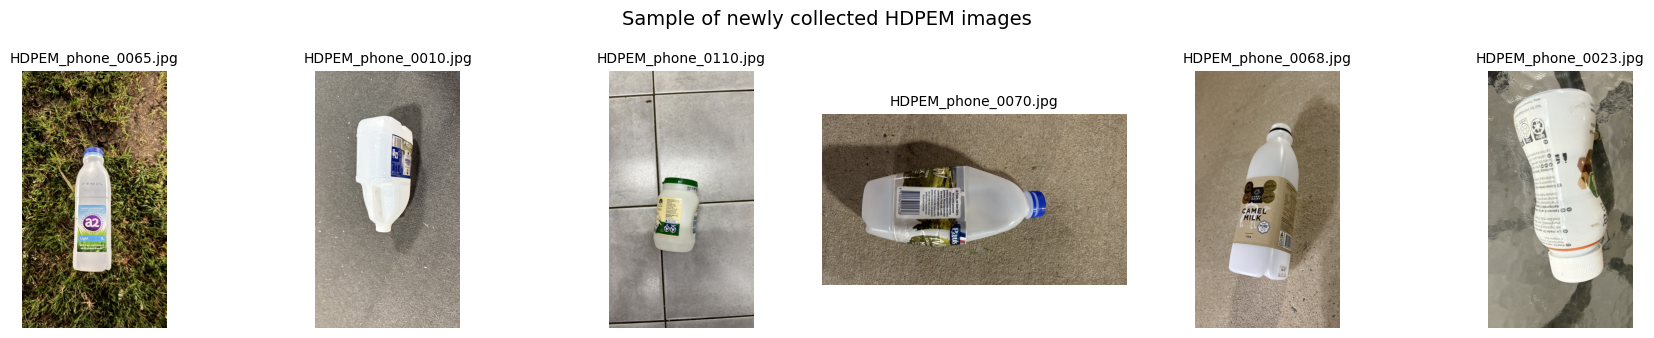

In [266]:
# Show a handful of the newly collected HDPEM photos, titled by filename, as a quick sanity check.
sample_new_paths = new_hdpem_df["path"].sample(6, random_state=SEED).tolist()
fig, axes = plt.subplots(1, len(sample_new_paths), figsize=(3 * len(sample_new_paths), 3.4))
for ax, rel_path in zip(axes, sample_new_paths):
    img = load_image_rgb(os.path.join(DATA_ROOT, rel_path))
    ax.imshow(img)
    ax.axis("off")
    ax.set_title(os.path.basename(rel_path), fontsize=10)
fig.suptitle("Sample of newly collected HDPEM images", fontsize=14)
plt.tight_layout()
plt.show()

### 3.2 Even out the class distribution

In [267]:
# Pick the better Part 2 system by macro-F1 (accuracy is misleading on this imbalanced test set). Chosen here because it sets the image size / normalisation used below.
if resnet_results["macro_f1"] >= cnn_results["macro_f1"]:
    best_name = "ResNet18"
    best_model_before = resnet_model
    best_img_size = RESNET_IMG_SIZE
    best_normalize = IMAGENET_NORMALIZE
    before_results = resnet_results
else:
    best_name = "Custom CNN"
    best_model_before = cnn_model
    best_img_size = CNN_IMG_SIZE
    best_normalize = None
    before_results = cnn_results

print(f"Best system from Part 2 (by macro-F1): {best_name}")
print(f"  before fine-tuning -- accuracy={before_results['accuracy']:.4f}, "
      f"macro-F1={before_results['macro_f1']:.4f}")

Best system from Part 2 (by macro-F1): ResNet18
  before fine-tuning -- accuracy=0.9242, macro-F1=0.9010


In [268]:
# Balance the training set in memory: RepeatedDataset cycles HDPEM up to the majority
# size, TransformDataset re-augments it per access, ConcatDataset joins the two streams.

class RepeatedDataset(Dataset):
    """Cycles a base dataset to `target_length` items (index i -> i % len(base))."""

    def __init__(self, base_dataset, target_length):
        super().__init__()
        self.dataset = base_dataset
        self.target_length = target_length

    def __len__(self):
        return self.target_length

    def __getitem__(self, idx):
        return self.dataset[idx % len(self.dataset)]


class TransformDataset(Dataset):
    """Wraps a dataset and applies an optional transform to every sample on the fly."""

    def __init__(self, base_dataset, transform=None):
        super().__init__()
        self.dataset = base_dataset
        self.transform = transform

    def __len__(self):
        return len(self.dataset)

    def __getitem__(self, idx):
        x, y = self.dataset[idx]
        if self.transform is not None:
            x = self.transform(x)
        return x, y


# Augment on the [0, 1] image, then normalise (ColorJitter/RandomAffine assume [0, 1]
# pixels, not baked-in normalisation). hue is kept small so colours stay realistic.
hdpem_augment_ops = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ColorJitter(brightness=(0.8, 1.2), contrast=(0.8, 1.2),
                            saturation=(0.8, 1.2), hue=0.05),
    transforms.RandomAffine(degrees=15, translate=(0.05, 0.1), scale=(0.9, 1.1)),
])

# HDPEM training transform: augment, then apply the model's normalisation (if any).
if best_normalize is not None:
    hdpem_train_transform = transforms.Compose([hdpem_augment_ops, best_normalize])
else:
    hdpem_train_transform = hdpem_augment_ops

print("Training-set class counts BEFORE augmentation:")
before_counts = train_task3_df["label"].value_counts().reindex(CLASSES)
print(before_counts)

non_hdpem_df = train_task3_df[train_task3_df["label"] != "HDPEM"].reset_index(drop=True)
hdpem_df = train_task3_df[train_task3_df["label"] == "HDPEM"].reset_index(drop=True)

target_count = int(non_hdpem_df["label"].value_counts().mean())  # match the other 3 classes
print(f"\nTarget per class: {target_count} (mean size of the other 3 classes)")

# Majority classes: normalised, not augmented.
non_hdpem_ds = WasteDataset(non_hdpem_df, DATA_ROOT, CLASSES, best_img_size, normalize=best_normalize)
# HDPEM: un-normalised base; hdpem_train_transform augments then normalises per access.
hdpem_base_ds = WasteDataset(hdpem_df, DATA_ROOT, CLASSES, best_img_size, normalize=None)
hdpem_repeated_ds = RepeatedDataset(hdpem_base_ds, target_length=target_count)
hdpem_balanced_ds = TransformDataset(hdpem_repeated_ds, transform=hdpem_train_transform)

train_balanced_ds = ConcatDataset([non_hdpem_ds, hdpem_balanced_ds])
train_balanced_loader = DataLoader(train_balanced_ds, batch_size=BATCH_SIZE, shuffle=True)

after_counts = before_counts.copy()
after_counts["HDPEM"] = target_count
print("\nTraining-set class counts AFTER augmentation (HDPEM oversampled+augmented up to "
      "the other classes' size; every access is freshly re-augmented, so this is a lower "
      "bound on the visual variety the model actually sees during training):")
print(after_counts)
print(f"\nTotal balanced training set size: {len(train_balanced_ds)}")

Training-set class counts BEFORE augmentation:
label
AluCan    600
Glass     600
HDPEM     210
PET       600
Name: count, dtype: int64

Target per class: 600 (mean size of the other 3 classes)

Training-set class counts AFTER augmentation (HDPEM oversampled+augmented up to the other classes' size; every access is freshly re-augmented, so this is a lower bound on the visual variety the model actually sees during training):
label
AluCan    600
Glass     600
HDPEM     600
PET       600
Name: count, dtype: int64

Total balanced training set size: 2400


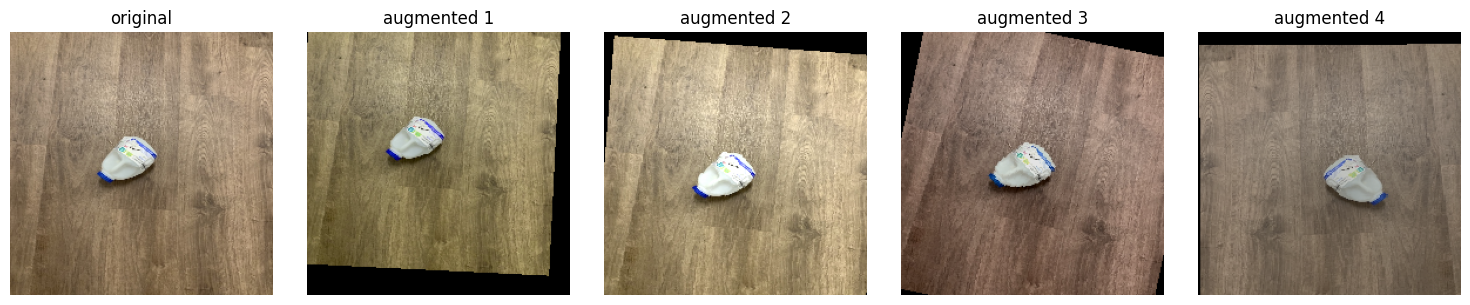

In [269]:
# One original HDPEM image beside four augmented versions (augmentation only, no
# normalisation, so the panels display as real photos).
hdpem_display_ds = WasteDataset(hdpem_df, DATA_ROOT, CLASSES, best_img_size, normalize=None)
original_tensor, _ = hdpem_display_ds[0]

fig, axes = plt.subplots(1, 5, figsize=(15, 3))
axes[0].imshow(original_tensor.permute(1, 2, 0).numpy())
axes[0].set_title("original")
axes[0].axis("off")
for i in range(1, 5):
    augmented_tensor = hdpem_augment_ops(original_tensor)
    axes[i].imshow(augmented_tensor.clamp(0, 1).permute(1, 2, 0).numpy())
    axes[i].set_title(f"augmented {i}")
    axes[i].axis("off")
plt.tight_layout()
plt.show()

**Why these transformations, and why not augment devtest/test.**

- `RandomHorizontalFlip`: drink containers have no fixed left/right orientation in a photo,
  so a flipped image is still a completely realistic photo of the same object -- this
  effectively doubles the useful viewpoints for free.
- `ColorJitter` (brightness/contrast/saturation/hue) and `RandomAffine` (small
  rotation/translation/scale jitter): approximate the lighting and camera-angle/framing
  variation we introduced on purpose while capturing the webcam/phone images (and that
  naturally exists between the original dataset photos and our own). Brightness/contrast/
  saturation are jittered by +/-20%, while **hue is jittered only by +/-0.05**: a small
  shift that mimics white-balance differences between cameras without recolouring the
  object or background into shades that would never occur in a real photo (an aggressive
  hue jitter produces, e.g., bright-green or magenta floors, which would contradict the
  goal of matching the original data's style).
- **Order: augment first, normalise last.** The augmentation runs while the image is still
  a plain `[0, 1]` RGB tensor, and the model's ImageNet normalisation is applied *after* it
  (`hdpem_train_transform = Compose([hdpem_augment_ops, IMAGENET_NORMALIZE])`).
  `ColorJitter`'s hue conversion and `RandomAffine`'s zero-fill are only meaningful on real
  pixel values in `[0, 1]`, not on already-standardised tensors that contain negative
  numbers, so normalising first would distort the augmentation.
- We deliberately did **not** use `RandomVerticalFlip`: bottles and cans are always
  photographed upright in this dataset, so an upside-down image would not be a realistic
  photo and could teach the model a misleading pattern.
- Because `TransformDataset` applies the transform **inside `__getitem__`**, every time a
  `RepeatedDataset`-cycled HDPEM image is drawn during training it gets an independently
  random augmentation -- so across many training epochs the model effectively sees far more
  than `target_count` distinct augmented views, not `target_count` fixed images.

Augmenting devtest or test would be wrong because those sets exist to estimate how the
model performs on **real, unseen photos** -- that is the whole point of holding them out
from training. If we applied the same random transformations to them, we would no longer be
measuring generalisation to genuine new images; we would just be measuring how well the
model handles our specific augmentation pipeline, which is not what we ultimately care
about (real-world deployment images will not have been through this exact pipeline). It
would also make test results non-reproducible run-to-run purely due to random augmentation,
rather than reflecting a fixed, comparable benchmark. This is exactly why `WasteDataset` for
devtest/test above is never wrapped in `TransformDataset`.

### 3.3 Fine-tuning and testing

As in 2.2, the ResNet18 backbone stays frozen throughout this step; only the classification
head is retrained, now on the balanced training set from 3.2. So "fine-tuning" here means
re-fitting the head's decision boundary to the now-equal classes, not adjusting the
convolutional features themselves -- this keeps the comparison with Part 2 fair (identical
frozen features throughout) and avoids catastrophic forgetting. An earlier attempt at
unfreezing the backbone was tried and collapsed HDPEM recall entirely, which is why the
backbone stays frozen here too.

Epoch  1: train_loss=0.2490 train_acc=0.9179 | val_loss=0.2154 val_acc=0.9403 | val_macro_f1=0.9159


Epoch  2: train_loss=0.1929 train_acc=0.9450 | val_loss=0.2148 val_acc=0.9323 | val_macro_f1=0.9007


Epoch  3: train_loss=0.1767 train_acc=0.9463 | val_loss=0.2057 val_acc=0.9290 | val_macro_f1=0.9023


Epoch  4: train_loss=0.1582 train_acc=0.9508 | val_loss=0.1946 val_acc=0.9339 | val_macro_f1=0.8952


Epoch  5: train_loss=0.1427 train_acc=0.9592 | val_loss=0.2140 val_acc=0.9274 | val_macro_f1=0.8871


Epoch  6: train_loss=0.1385 train_acc=0.9554 | val_loss=0.1936 val_acc=0.9323 | val_macro_f1=0.8893
No devtest improvement for 5 epochs -- stopping early at epoch 6 (best val_macro_f1=0.9159).


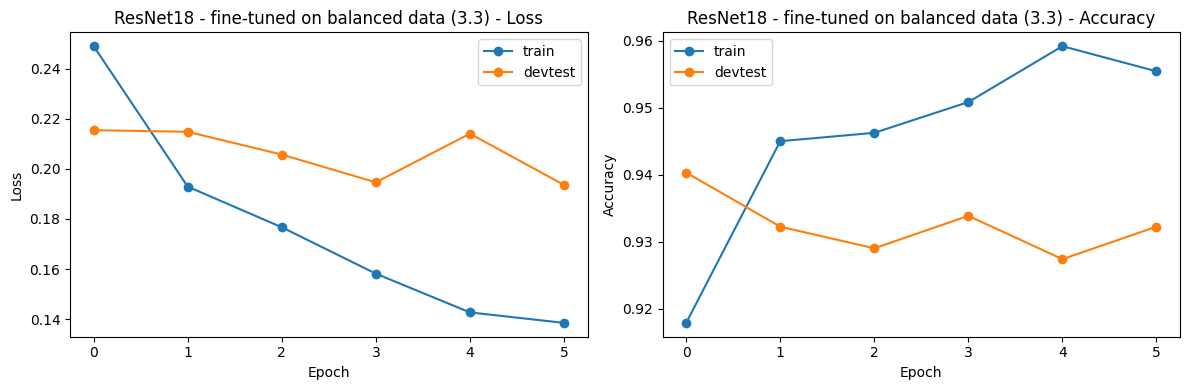

In [270]:
# Fine-tune a copy of the best model on the balanced set; the backbone stays frozen (as
# in 2.2) and only the head is retrained, with early stopping on the Part 2 devtest set.

finetune_model = copy.deepcopy(best_model_before).to(device)

devtest_loader_best = devtest_loader_resnet if best_name == "ResNet18" else devtest_loader_cnn
test_loader_best = test_loader_resnet if best_name == "ResNet18" else test_loader_cnn

if best_name == "ResNet18":
    for param in finetune_model.parameters():
        param.requires_grad = False
    for param in finetune_model.fc.parameters():
        param.requires_grad = True
    finetune_history = fit(finetune_model, train_balanced_loader, devtest_loader_best, device,
                           max_epochs=30, patience=5, lr=1e-3, monitor="macro_f1")
else:
    # The CNN has no frozen backbone: "fine-tuning" is just continued training at a lower
    # learning rate on the balanced set.
    finetune_history = fit(finetune_model, train_balanced_loader, devtest_loader_best, device,
                           max_epochs=30, patience=5, lr=1e-4, monitor="macro_f1")

plot_history(finetune_history, f"{best_name} - fine-tuned on balanced data (3.3)")

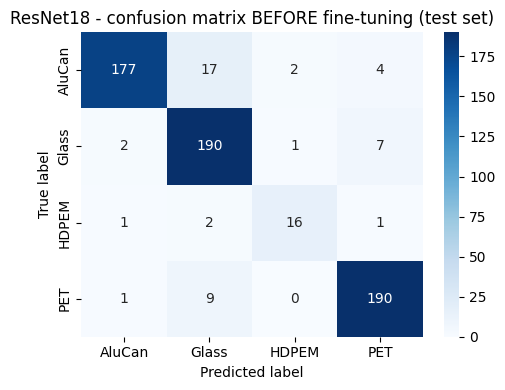

In [271]:
# Confusion matrix before fine-tuning (same model and test set as Part 2.3).
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(before_results["confusion_matrix"], annot=True, fmt="d", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES, ax=ax)
ax.set_xlabel("Predicted label")
ax.set_ylabel("True label")
ax.set_title(f"{best_name} - confusion matrix BEFORE fine-tuning (test set)")
plt.tight_layout()
plt.show()

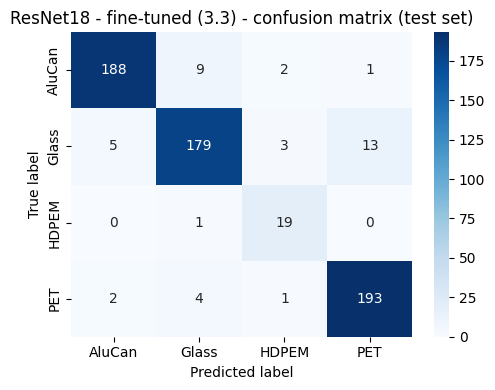


ResNet18 - fine-tuned (3.3) - test set metrics


,class,accuracy,macro_F1,recall,test images (support)
0,AluCan,0.933871,0.913922,0.940,200
1,Glass,0.933871,0.913922,0.895,200
2,HDPEM,0.933871,0.913922,0.950,20
3,PET,0.933871,0.913922,0.965,200
Overall,Overall,0.933871,0.913922,NaN,620


Most common error: true='Glass' predicted as 'PET' (13 test images)


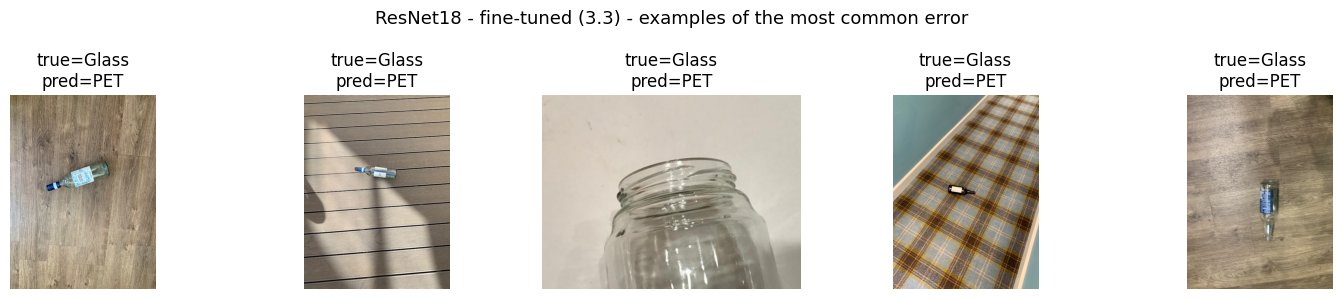

In [272]:
# Re-run the same error analysis on the fine-tuned model, so the before/after comparison below uses identical metrics.
after_results = error_analysis(finetune_model, f"{best_name} - fine-tuned (3.3)",
                               test_loader_best, test_df, device)


In [273]:
# Tabulate per-class recall plus overall accuracy/macro-F1 before vs. after fine-tuning, for the Part 3.3 discussion.
comparison = pd.DataFrame({
    "class": CLASSES,
    "recall (before)": recall_score(before_results["y_true"], before_results["y_pred"],
                                     average=None, labels=range(len(CLASSES))),
    "recall (after)": recall_score(after_results["y_true"], after_results["y_pred"],
                                    average=None, labels=range(len(CLASSES))),
})
comparison["recall (change)"] = comparison["recall (after)"] - comparison["recall (before)"]

summary_row = pd.DataFrame({
    "class": ["Overall"],
    "recall (before)": [np.nan], "recall (after)": [np.nan], "recall (change)": [np.nan],
})
comparison = pd.concat([comparison, summary_row], ignore_index=True)
comparison.loc[comparison["class"] == "Overall", "accuracy (before)"] = before_results["accuracy"]
comparison.loc[comparison["class"] == "Overall", "accuracy (after)"] = after_results["accuracy"]
comparison.loc[comparison["class"] == "Overall", "macro_F1 (before)"] = before_results["macro_f1"]
comparison.loc[comparison["class"] == "Overall", "macro_F1 (after)"] = after_results["macro_f1"]

display(comparison)


,class,recall (before),recall (after),recall (change),accuracy (before),accuracy (after),macro_F1 (before),macro_F1 (after)
0,AluCan,0.885,0.940,0.055,NaN,NaN,NaN,NaN
1,Glass,0.950,0.895,-0.055,NaN,NaN,NaN,NaN
2,HDPEM,0.800,0.950,0.150,NaN,NaN,NaN,NaN
3,PET,0.950,0.965,0.015,NaN,NaN,NaN,NaN
4,Overall,NaN,NaN,NaN,0.924194,0.933871,0.901003,0.913922


**1. How HDPEM recall changed, and what happened to the other three classes; accuracy vs. macro-F1.**

| Metric | Before fine-tuning | After fine-tuning | Change |
|---|---|---|---|
| Accuracy | 92.42% | 93.39% | +0.97 pts |
| Macro-F1 | 90.10% | 91.39% | +1.29 pts |
| AluCan recall | 88.5% | 94.0% | +5.5 pts |
| Glass recall | 95.0% | 89.5% | -5.5 pts |
| HDPEM recall | 80.0% (16/20) | 95.0% (19/20) | +15.0 pts (3 images) |
| PET recall | 95.0% | 96.5% | +1.5 pts |

HDPEM recall improved substantially, from 16/20 to 19/20 correct (+15 percentage points):
the rebalanced, augmented training set gave the classification head enough minority-class
signal to stop under-predicting HDPEM. Among the other three classes, AluCan (+5.5) and PET
(+1.5) also improved while Glass regressed by 5.5 points, so the net movement of the
majority classes is close to flat and the headline gain is essentially the HDPEM
improvement.

**Macro-F1 moved slightly more than accuracy (+1.29 vs +0.97 points), and this time both
moved in the same, positive direction.** This is the imbalance effect from Part 2.3 again:
HDPEM is only ~3.2% of the test set, so its 3 extra correct images lift overall accuracy by
only ~0.5 points, but macro-F1 averages the four per-class F1 scores equally, so a large
gain on the smallest class shows up strongly. The rest of accuracy's movement comes from the
majority classes (AluCan +11 images, PET +3, Glass -11), which roughly cancel. A
fine-tuning step that mainly helps the minority class will always register more clearly in
macro-F1 than in accuracy.

Two caveats on interpreting this. First, 3 images out of 20 is a real improvement but still
a small-sample figure (each HDPEM image is worth 5 recall points), so "clearly better" is a
safer reading than a precise 95%. Second, early stopping on devtest macro-F1 selected
**epoch 1** (val macro-F1 0.916, declining afterwards): with the backbone frozen exactly as
in 2.2 and only the classification head training, a single pass over the balanced data was
enough to re-centre the head's decision boundaries onto the four now-equal classes, and
later epochs began to overfit the augmented HDPEM images.

**2. Confusion matrix comparison with Part 2.3.**

Comparing ResNet18's "before" matrix (re-displayed above) with the "after" matrix:

- **Errors that became less common.** `AluCan` -> `Glass` fell from 17 to 9, and AluCan's
  total errors fell from 23/200 to 12/200. `HDPEM` errors fell from 4/20 to 1/20 (the single
  remaining HDPEM error is one bottle predicted as `Glass`). These are exactly the two weak
  spots Part 2.3 identified, and both improved. `PET` errors also dropped slightly, from
  10/200 to 7/200.
- **Errors that became more common.** `Glass` -> `PET` rose from 7 to 13 and is now the
  single most common error; Glass's total errors rose from 10/200 to 21/200, so Glass has
  replaced AluCan as the weakest majority class.

So fine-tuning on the balanced set did not simply shrink the whole matrix uniformly: it
clearly reduced the minority-class and AluCan/Glass errors it was aimed at, at the cost of a
moderate rise in `Glass` -> `PET` confusion. The overall effect is still a net improvement
(accuracy and macro-F1 both up, HDPEM recall up 15 points) -- in contrast to the earlier
attempts that unfroze the backbone and collapsed HDPEM recall. Keeping the backbone frozen
and re-training only the head on rebalanced, augmented data is what made the gain stable
rather than destructive.

## Notes

Generative AI tools (ChatGPT and GitHub Copilot) were used for proofreading the written
cells and for help with a few helper pieces (`class_counts_table`, `plot_history`, the
webcam/phone capture scripts, and the dropout-ablation cell), as well as for diagnosing a
bug in the first version of the Part 3.2 augmentation pipeline. The models, dataset
classes, training loop, evaluation logic and analysis are my own.
